In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F

Vocabulary = {"Attention" : 0, "is" : 1, "all" : 5, "you" : 2, "need" : 3, "!" : 6, "," : 4}

sentence = "Attention is all you need !"
tokens = sentence.split()

token_ids = []

for token in tokens:
    token_ids.append(Vocabulary[token])

#Here we define the target ids by shifting the token_ids by one element to the left.  
target_ids = token_ids[1:]
#input delets the last cell. For our example being "!". 
input_ids = token_ids[:-1]

#Then we convert this ordinary list into torch tensor.
input_ids = torch.tensor(input_ids, dtype = torch.long)
target_ids = torch. tensor(target_ids, dtype = torch.long)

#Here we deine the variables, that we will later use to define matrices. 
#N = len(token_ids) size of tokens, but it's not needed to define inside init function. Later we will define it in forward functino using shape[0]. I just mention what it was so I won't forget to define in forward function. 
V = len(Vocabulary) #vocab size
d_model = V
d_k = 4
d_v = 5


loss_history = []

#A class describes objects that can store information. 
class ToyAttentionModel(nn.Module):

    #Here we define a special function attached to a class. 
    def __init__(self, vocab_size, d_model, d_k, d_v): 
        super().__init__()

        #definint E
        self.embedding = nn.Embedding(vocab_size, d_model)
        #defining W_Q
        self.query = nn.Linear(d_model, d_k, bias = False)
        #W_K
        self.key = nn.Linear(d_model, d_k, bias = False)
        #W_V
        self.value = nn.Linear(d_model, d_v, bias = False)
        #W_vocab
        self.output = nn.Linear(d_v, vocab_size, bias = False)
    # Here I define forward function. 
    def forward(self, input_ids):
        X = self.embedding(input_ids)
        Q = self.query(X)
        K = self.key(X)
        V_values = self.value(X) #X @ W_V
        d_k = Q.shape[1]
        S = (Q @ K.T)/(d_k **(0.5)) #score calculation
        N = input_ids.shape[0] # number of tokens
        M = torch.full((N,N), float("-inf"), dtype = X.dtype, device = X.device)#caueal Masking being defined to make current approximation independent of future tokens.
        M = torch.triu(M, diagonal = 1)
        A = torch.softmax(S + M, dim = 1)
        O = A @ V_values
        Z = self.output(O) #getting back to the definition of self.output, we defined as Linear(d_v, vocab_size), so it takes Z = O @ W_vocab, which we called this W_vocab as self.output.  
    
        #return X, Q, K, V_values, A, O, Z, well I only need logits. Just wanted to check for dimension and that everything works fine, which did. So, now I only have forward to return logits(Z).
        return Z

torch.manual_seed(0)
#here we first instantiate the model by calling it, and naming it model. 
model = ToyAttentionModel(
    vocab_size=V,
    d_model=d_model,
    d_k=d_k,
    d_v=d_v
)
for name, parameter in model.named_parameters():
    print(name, parameter.shape)





embedding.weight torch.Size([7, 7])
query.weight torch.Size([4, 7])
key.weight torch.Size([4, 7])
value.weight torch.Size([5, 7])
output.weight torch.Size([7, 5])


In [32]:
# Run the completed forward pass and verify that its logits match the targets.
logits = model(input_ids)

print("input_ids shape:", input_ids.shape)
print("target_ids shape:", target_ids.shape)
print("logits shape:", logits.shape)


input_ids shape: torch.Size([5])
target_ids shape: torch.Size([5])
logits shape: torch.Size([5, 7])


In [33]:
model.parameters()


<generator object Module.parameters at 0x119296dc0>

In [34]:
optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)

for steps in range(1000):

    optimizer.zero_grad() 

    logits = model(input_ids)
    loss = F.cross_entropy(logits, target_ids)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if steps % 100 == 0:
        print(steps, loss.item())

0 1.970158576965332
100 0.402127742767334
200 0.09537708759307861
300 0.032878030091524124
400 0.016893263906240463
500 0.010672932490706444
600 0.007549244910478592
700 0.0057282522320747375
800 0.004557458218187094
900 0.0037513202987611294


In [35]:
#here we do reverse thing, to actually make prediction using loss history. 

id_to_token = {
    token_id: token
    for token, token_id in Vocabulary.items()
}

with torch.no_grad():
    logits = model(input_ids)
    predicted_ids = torch.argmax(logits, dim=1)


#translate the IDs back into tokens. 

predicted_tokens = []

for token_id in predicted_ids:
    predicted_tokens.append(id_to_token[token_id.item()])

print("Predicted:", predicted_tokens)


Predicted: ['is', 'all', 'you', 'need', '!']


In [36]:
training_sentences = ["I love math !","You love attention !", "We love math !"]
validation_sentence = "We love attention !"
vocabulary = { "I": 0, "love": 1, "math": 2, "We": 3, "You": 4, "!": 5, "attention": 6} 


def encode_sentence(sentence, vocabulary):
    token_ids = []
    tokens = sentence.split()
    for token in tokens:
        token_ids.append(vocabulary[token])
    shifted_inputs = token_ids[:-1]
    shifted_targets = token_ids[1:]
    shifted_inputs = torch.tensor(shifted_inputs, dtype = torch.long)
    shifted_targets = torch.tensor(shifted_targets, dtype = torch.long)

    return shifted_inputs, shifted_targets


shifted_inputs, shifted_targets = encode_sentence( "I love math !", vocabulary)

print(shifted_inputs)
print(shifted_targets)


        


tensor([0, 1, 2])
tensor([1, 2, 5])


In [37]:
import numpy as np
vocab_size = len(vocabulary)

d_model = vocab_size
d_k = 4
d_v = 5

total_training_loss = 0

torch.manual_seed(0)
model = ToyAttentionModel(
    vocab_size = vocab_size,
    d_model = d_model,
    d_k = d_k,
    d_v = d_v
)
optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)
loss_history = []

for epoch in range(501): 
    total_training_loss = 0
    
    for sentence in training_sentences:
        optimizer.zero_grad()
        inputs, targets = encode_sentence(sentence, vocabulary)
        logits = model(inputs)
        loss = F.cross_entropy(logits, targets)
        loss.backward()
        optimizer.step()
        total_training_loss += loss.item()

    average_loss = total_training_loss/ len(training_sentences)
    loss_history.append(average_loss)
    if epoch% 50 == 0:
        print(epoch, average_loss)

    





0 2.00623087088267
50 0.045100510120391846
100 0.009842957758034268
150 0.004912674737473329
200 0.003136761370114982
250 0.0022554185319071016
300 0.0017386909069803853
350 0.0014029565209057182
400 0.0011691704761081685
450 0.0009979515355856468
500 0.0008675946446601301


In [38]:
model.eval()

validation_inputs, validation_targets = encode_sentence(
    validation_sentence,
    vocabulary
)

with torch.no_grad():
    validation_logits = model(validation_inputs)
    validation_loss = F.cross_entropy(
        validation_logits,
        validation_targets
    )

print("Final training loss:", loss_history[-1])
print("Validation loss:", validation_loss.item())

Final training loss: 0.0008675946446601301
Validation loss: 2.5606672763824463


In [39]:
# ---------------------------------------------------------------------------
# HELD-OUT VALIDATION AND PREDICTION DECODING
#
# The model was trained on several sentences, but it was not trained on
# `validation_sentence`. We now evaluate whether it can use patterns learned
# from the training sentences on this unseen combination of words.
#
# First, we reverse the vocabulary dictionary. The original vocabulary maps
# tokens to integer IDs:
#
#     token -> ID
#
# The reverse dictionary maps predicted IDs back to readable tokens:
#
#     ID -> token
#
# Next, `encode_sentence` converts the validation sentence into shifted
# input and target tensors. For example:
#
#     complete sentence:  We love attention !
#     model inputs:       We love attention
#     correct targets:    love attention !
#
# `model.eval()` puts the model into evaluation mode. This matters for layers
# such as dropout and batch normalization. Our current model does not contain
# those layers, so its numerical behavior does not change, but using eval mode
# is the correct general practice during validation.
#
# `torch.no_grad()` prevents PyTorch from constructing a computational graph.
# Validation only measures the trained model's performance; it must not
# calculate gradients or update parameters. Therefore, this section contains
# no `loss.backward()` and no `optimizer.step()`.
#
# The model returns `validation_logits`. Each row contains one unnormalized
# score for every vocabulary token. Cross-entropy compares those logits with
# the correct validation target IDs:
#
#     validation_loss = F.cross_entropy(
#         validation_logits,
#         validation_targets
#     )
#
# `torch.argmax(validation_logits, dim=1)` selects the vocabulary column with
# the largest logit in every row. These selected column indices are the
# model's predicted next-token IDs.
#
# Finally, we use `id_to_token` to translate the target and predicted IDs back
# into readable words. We print the final training loss and validation loss
# together:
#
# - A very small training loss means the model learned the training examples.
# - A small validation loss means it also handled the unseen sentence well.
# - A small training loss but large validation loss indicates overfitting:
#   the model memorized training combinations without fully learning a rule
#   that generalizes to the held-out combination.
#
# `loss_history` is only a record of training losses for analysis or plotting.
# The predictions are produced using the model's final trained parameters.
# ---------------------------------------------------------------------------


id_to_token = {
    token_id: token
    for token, token_id in vocabulary.items()
}

validation_inputs, validation_targets = encode_sentence(
    validation_sentence,
    vocabulary
)

model.eval()
with torch.no_grad():
    validation_logits = model(validation_inputs)
    validation_loss = F.cross_entropy(validation_logits, validation_targets)
    predicted_ids = torch.argmax(validation_logits, dim=1)
    


#translate the IDs back into tokens. 
target_tokens = []
for token_id in validation_targets:
    target_tokens.append(id_to_token[token_id.item()])

predicted_tokens = []
for token_id in predicted_ids:
    predicted_tokens.append(id_to_token[token_id.item()])

print("Final training loss:", loss_history[-1])
print("Validation loss:", validation_loss.item())
print("Targets:", target_tokens)
print("Predicted:", predicted_tokens)


Final training loss: 0.0008675946446601301
Validation loss: 2.5606672763824463
Targets: ['love', 'attention', '!']
Predicted: ['love', 'math', '!']


In [ ]:
# Start a fresh, reproducible experiment so both histories align.
torch.manual_seed(0)
model = ToyAttentionModel(
    vocab_size=vocab_size,
    d_model=d_model,
    d_k=d_k,
    d_v=d_v
)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
loss_history = []
validation_loss_history = []

for epoch in range(501):
    model.train()
    total_training_loss = 0

    for sentence in training_sentences:
        optimizer.zero_grad()

        inputs, targets = encode_sentence(
            sentence,
            vocabulary
        )

        logits = model(inputs)
        loss = F.cross_entropy(logits, targets)

        loss.backward()
        optimizer.step()

        total_training_loss += loss.item()

    average_loss = (
        total_training_loss / len(training_sentences)
    )
    loss_history.append(average_loss)

    model.eval()

    validation_inputs, validation_targets = encode_sentence(
        validation_sentence,
        vocabulary
    )

    with torch.no_grad():
        validation_logits = model(validation_inputs)
        validation_loss = F.cross_entropy(
            validation_logits,
            validation_targets
        )

    validation_loss_history.append(
        validation_loss.item()
    )

    if epoch % 50 == 0:
        print(
            epoch,
            average_loss,
            validation_loss.item()
        )

print("Training history length:", len(loss_history))
print("Validation history length:", len(validation_loss_history))


0 2.00623087088267 2.03228759765625
50 0.045100510120391846 1.2418185472488403
100 0.009842957758034268 1.7175631523132324
150 0.004912674737473329 1.968942642211914
200 0.003136761370114982 2.1235461235046387
250 0.0022554185319071016 2.2363035678863525
300 0.0017386909069803853 2.3249330520629883
350 0.0014029565209057182 2.3978331089019775
400 0.0011691704761081685 2.4596738815307617
450 0.0009979515355856468 2.5133206844329834
500 0.0008675946446601301 2.5606672763824463
Training history length: 501
Validation history length: 501


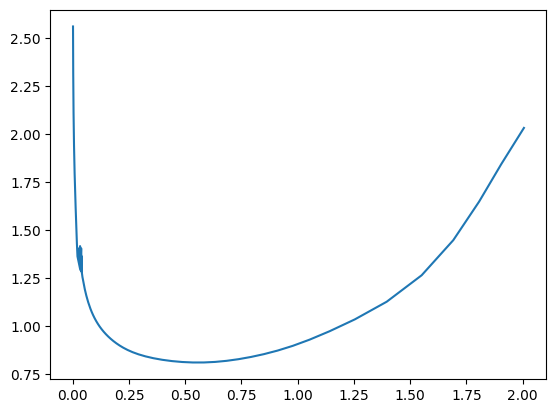

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.plot(loss_history,validation_loss_history)




range(0, 501)


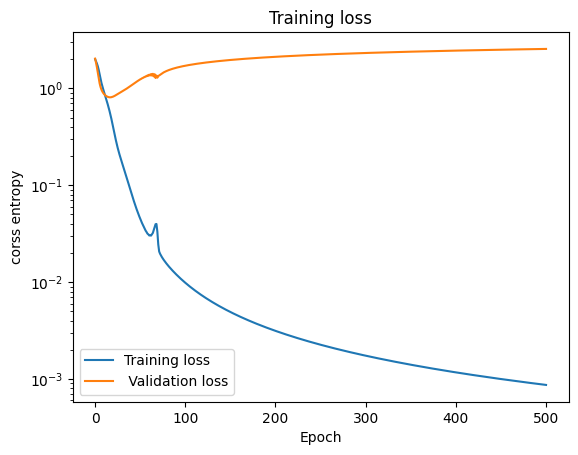

In [46]:
epochs = range(len(loss_history))

plt.plot(epochs, loss_history, label = "Training loss")
plt.plot(epochs, validation_loss_history, label = " Validation loss")

plt.xlabel("Epoch")
plt.ylabel("corss entropy")

plt.yscale("log")
plt.legend()
plt.title("Training loss")

plt.show()



In [51]:
best_epoch = np.argmin(validation_loss_history)
best_validation_loss_history = validation_loss_history[best_epoch]

print(best_epoch, best_validation_loss_history)
print(loss_history[17])

for i in range(100): 
    print(i, loss_history[i], validation_loss_history[i])
    

17 0.8103606104850769
0.5340290367603302
0 2.00623087088267 2.03228759765625
1 1.9053328037261963 1.8433847427368164
2 1.807012637456258 1.648488163948059
3 1.691960056622823 1.447337031364441
4 1.551361878712972 1.2646334171295166
5 1.3959136803944905 1.126799464225769
6 1.2542418837547302 1.0348645448684692
7 1.1419315139452617 0.9731186032295227
8 1.0530335903167725 0.9292859435081482
9 0.9779461820920309 0.8968982100486755
10 0.9109510680039724 0.8724378943443298
11 0.8493766486644745 0.8536456227302551
12 0.7917773226896921 0.8389843106269836
13 0.7370521724224091 0.8275554180145264
14 0.684322769443194 0.8190045356750488
15 0.6330275932947794 0.8132918477058411
16 0.5829271525144577 0.8104367852210999
17 0.5340290367603302 0.8103606104850769
18 0.4865468144416809 0.8128514885902405
19 0.4409264450271924 0.8176125884056091
20 0.39787112424770993 0.8243200778961182
21 0.35825471580028534 0.8326519131660461
22 0.3228724127014478 0.8422772884368896
23 0.2921353379885356 0.85284757614

In [ ]:
import copy

# Start a fresh, reproducible experiment.
torch.manual_seed(0)

model = ToyAttentionModel(
    vocab_size=vocab_size,
    d_model=d_model,
    d_k=d_k,
    d_v=d_v
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1
)

loss_history = []
validation_loss_history = []

# Early-stopping state
best_validation_loss = float("inf")
best_epoch = None
best_model_state = None

patience = 20
epochs_without_improvement = 0


for epoch in range(501):
    # -------------------------------------------------------
    # TRAINING
    # -------------------------------------------------------
    model.train()
    total_training_loss = 0

    for sentence in training_sentences:
        inputs, targets = encode_sentence(
            sentence,
            vocabulary
        )

        optimizer.zero_grad()

        logits = model(inputs)
        loss = F.cross_entropy(logits, targets)

        loss.backward()
        optimizer.step()

        total_training_loss += loss.item()

    average_loss = (
        total_training_loss / len(training_sentences)
    )

    loss_history.append(average_loss)

    # -------------------------------------------------------
    # VALIDATION
    # -------------------------------------------------------
    model.eval()

    validation_inputs, validation_targets = encode_sentence(
        validation_sentence,
        vocabulary
    )

    with torch.no_grad():
        validation_logits = model(validation_inputs)

        validation_loss = F.cross_entropy(
            validation_logits,
            validation_targets
        )

    current_validation_loss = validation_loss.item()

    validation_loss_history.append(
        current_validation_loss
    )

    # -------------------------------------------------------
    # SAVE THE BEST MODEL
    # -------------------------------------------------------
    if current_validation_loss < best_validation_loss:
        best_validation_loss = current_validation_loss
        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    # Print progress.
    if epoch % 10 == 0:
        print(
            epoch,
            average_loss,
            current_validation_loss
        )

    # Stop after `patience` consecutive epochs without improvement.
    if epochs_without_improvement >= patience:
        print("Early stopping at epoch:", epoch)
        break


# -----------------------------------------------------------
# RESTORE THE PARAMETERS FROM THE BEST VALIDATION EPOCH
# -----------------------------------------------------------
model.load_state_dict(best_model_state)
model.eval()

print("Best epoch:", best_epoch)
print("Best validation loss:", best_validation_loss)
print("Training history length:", len(loss_history))
print(
    "Validation history length:",
    len(validation_loss_history)
)



0 2.00623087088267 2.03228759765625
10 0.9109510680039724 0.8724378943443298
20 0.39787112424770993 0.8243200778961182
30 0.16862907633185387 0.9335108399391174
Early stopping at epoch: 37
Best epoch: 17
Best validation loss: 0.8103606104850769
Training history length: 38
Validation history length: 38
